In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import geopandas as gpd
import geobr
from pathlib import Path
import sys
sys.path.append(str(Path.cwd().parent.parent))
from src.soja_clima.merge import carregar_base_final  # base única: base_final_modelagem.csv
from src.soja_clima.geo import mapa_estacoes_cd_micro  # mapa estação->microrregião em memória

PROCESSED_DIR = Path("../../data/processed")
df = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
df['data'] = pd.to_datetime(df['data'])

# Carrega o mapa para o caso de você querer usar nas próximas células
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.titlesize'] = 13

print("Shape:", df.shape)
print("Período:", df['data'].min().date(), "a", df['data'].max().date())
print("Estações:", df['codigo_estacao'].nunique(), "| UFs:", df['uf'].nunique(), "| Microrregiões (no mapa):", mapa['CD_MICRO'].nunique())

Shape: (3020460, 19)
Período: 2005-01-01 a 2026-09-30
Estações: 701 | UFs: 27 | Microrregiões (no mapa): 553


In [7]:
print("Nulos por coluna (%):")
nulos = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
print(nulos[nulos > 0])

print("\nEstatísticas descritivas (variáveis numéricas):")
colunas_num = ['prec_total', 'temp_media', 'temp_max', 'temp_min', 'umid_media', 
               'radiacao_total', 'vento_medio', 'amplitude_termica', 'gdd', 'dia_seco', 'n_horas_validas']
print(df[colunas_num].describe().round(2))

Nulos por coluna (%):
estacao        6.26
vento_medio    4.00
umid_media     1.72
dtype: float64

Estatísticas descritivas (variáveis numéricas):
       prec_total  temp_media    temp_max    temp_min  umid_media  \
count  3020460.00  3020460.00  3020460.00  3020460.00  2968586.00   
mean         3.54       23.31       28.98       18.94       74.89   
std         10.30        4.36        4.97        4.53       13.88   
min          0.00      -49.19      -48.10      -51.40        3.00   
25%          0.00       21.07       26.40       16.50       67.30   
50%          0.00       24.20       29.80       19.90       77.67   
75%          1.00       26.37       32.40       22.30       85.08   
max        414.60       44.74       45.00       44.40      100.00   

       radiacao_total  vento_medio  amplitude_termica         gdd    dia_seco  \
count      3020460.00   2899701.00         3020460.00  3020460.00  3020460.00   
mean         18776.82       154.42              10.04       13.98     

Gerando mapa de cobertura espacial do INMET...
Microrregiões COM estação: 553
Microrregiões SEM estação: 5


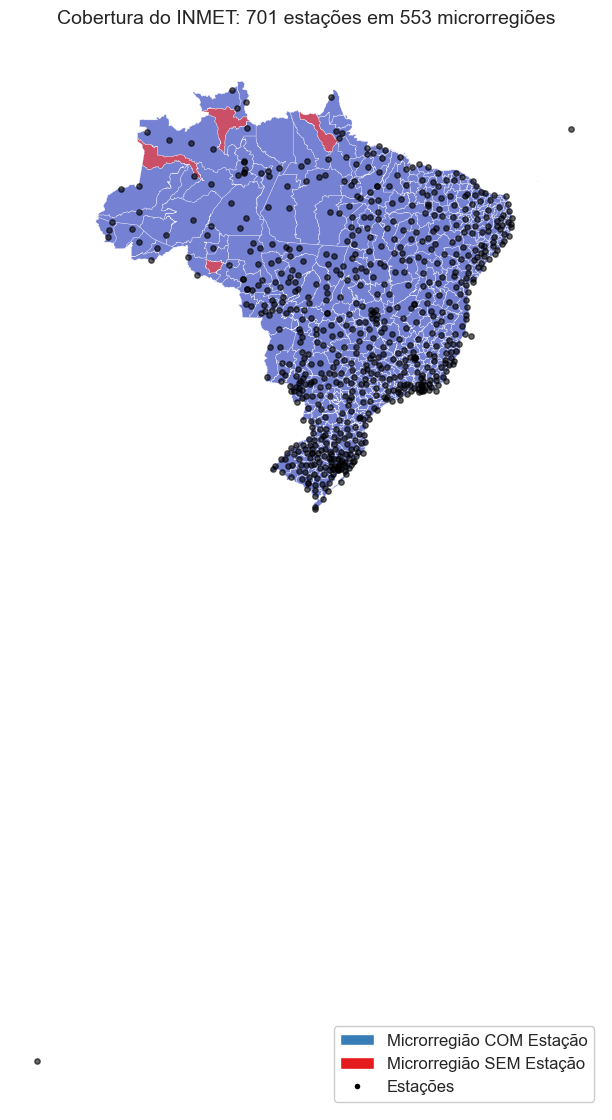

In [8]:
print("Gerando mapa de cobertura espacial do INMET...")

# 1. Pega as coordenadas únicas de cada estação
estacoes_geo = df.groupby('codigo_estacao').agg(
    VL_LATITUDE=('VL_LATITUDE', 'median'),
    VL_LONGITUDE=('VL_LONGITUDE', 'median')
).reset_index()

# 2. Carrega o mapa e PADRONIZA os dois lados como string
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)

# 3. CORREÇÃO AQUI: Remove os nulos antes de converter
mapa_limpo = mapa.dropna(subset=['CD_MICRO']).copy()
mapa_limpo['CD_MICRO'] = mapa_limpo['CD_MICRO'].astype(float).astype(int).astype(str)

micro_com_estacao = set(mapa_limpo['CD_MICRO'].unique())
gdf_micro['tem_estacao'] = gdf_micro['code_micro'].isin(micro_com_estacao)

# Diagnóstico rápido
print(f"Microrregiões COM estação: {gdf_micro['tem_estacao'].sum()}")
print(f"Microrregiões SEM estação: {(~gdf_micro['tem_estacao']).sum()}")

fig, ax = plt.subplots(figsize=(14, 14))
gdf_micro.plot(
    column='tem_estacao', 
    cmap='coolwarm_r', 
    legend=False, 
    edgecolor='white', 
    linewidth=0.3, 
    ax=ax,
    alpha=0.7
)
ax.scatter(
    estacoes_geo['VL_LONGITUDE'], 
    estacoes_geo['VL_LATITUDE'], 
    s=15, c='black', alpha=0.6, label='Estações INMET', zorder=5
)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#377eb8', label='Microrregião COM Estação'),
    Patch(facecolor='#e41a1c', label='Microrregião SEM Estação'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=5, label='Estações')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=12, framealpha=1)
ax.set_title(f'Cobertura do INMET: {len(estacoes_geo)} estações em {len(micro_com_estacao)} microrregiões', fontsize=14)
ax.axis('off')
plt.show()

In [9]:
print("Como as microrregiões foram preenchidas (coluna 'origem' do mapa):")
print(mapa['origem'].value_counts())

# Vendo as poucas microrregiões que FICARAM SEM NADA
micro_sem_estacao = set(gdf_micro['code_micro']) - set(mapa['CD_MICRO'].dropna().unique())
print(f"\nAinda ficaram {len(micro_sem_estacao)} microrregiões sem nenhuma estação (provavelmente no meio da Amazônia).")

Como as microrregiões foram preenchidas (coluna 'origem' do mapa):
origem
dentro_do_poligono          724
substituta_por_centroide    142
Name: count, dtype: int64

Ainda ficaram 558 microrregiões sem nenhuma estação (provavelmente no meio da Amazônia).




In [20]:
# 1. Cria a matriz de cobertura (na ordem original, sem ordenar)
cobertura = df.groupby(['codigo_estacao', 'ano']).size().unstack(fill_value=0)

# 2. Plota com Seaborn (sem forçar escala, sem ordenar)
plt.figure(figsize=(12, max(4, 0.35 * len(cobertura))))
sns.heatmap(
    cobertura, 
    cmap='YlGnBu', 
    cbar_kws={'label': 'Dias com dado válido'},
    linewidths=0,       # Remove as linhas brancas entre as células
    yticklabels=True    # Garante que os nomes das estações apareçam
)
plt.title('Cobertura diária por estação x ano', fontsize=14)
plt.xlabel('Ano')
plt.ylabel('Estação')
plt.tight_layout()
plt.show()

In [21]:
# Qual o tipo de cada estação (A = Automática, O = Convencional)?
df['tipo'] = df['codigo_estacao'].str[0]
print(df.groupby('tipo').agg(
    n_estacoes=('codigo_estacao', 'nunique'),
    media_horas_validas=('n_horas_validas', 'mean')
).round(1))

# Quantas estações ficaram totalmente vazias (0 dias)?
dias_por_estacao = df.groupby('codigo_estacao')['data'].count()
print(f"\nEstações com ZERO dias válidos: {(dias_por_estacao == 0).sum()}")
print(f"Estações com mais de 100 dias válidos: {(dias_por_estacao > 100).sum()}")

      n_estacoes  media_horas_validas
tipo                                 
A            609                 23.9
B             58                 23.6
C              1                 20.4
F              1                 24.0
S             32                 23.7

Estações com ZERO dias válidos: 0
Estações com mais de 100 dias válidos: 686


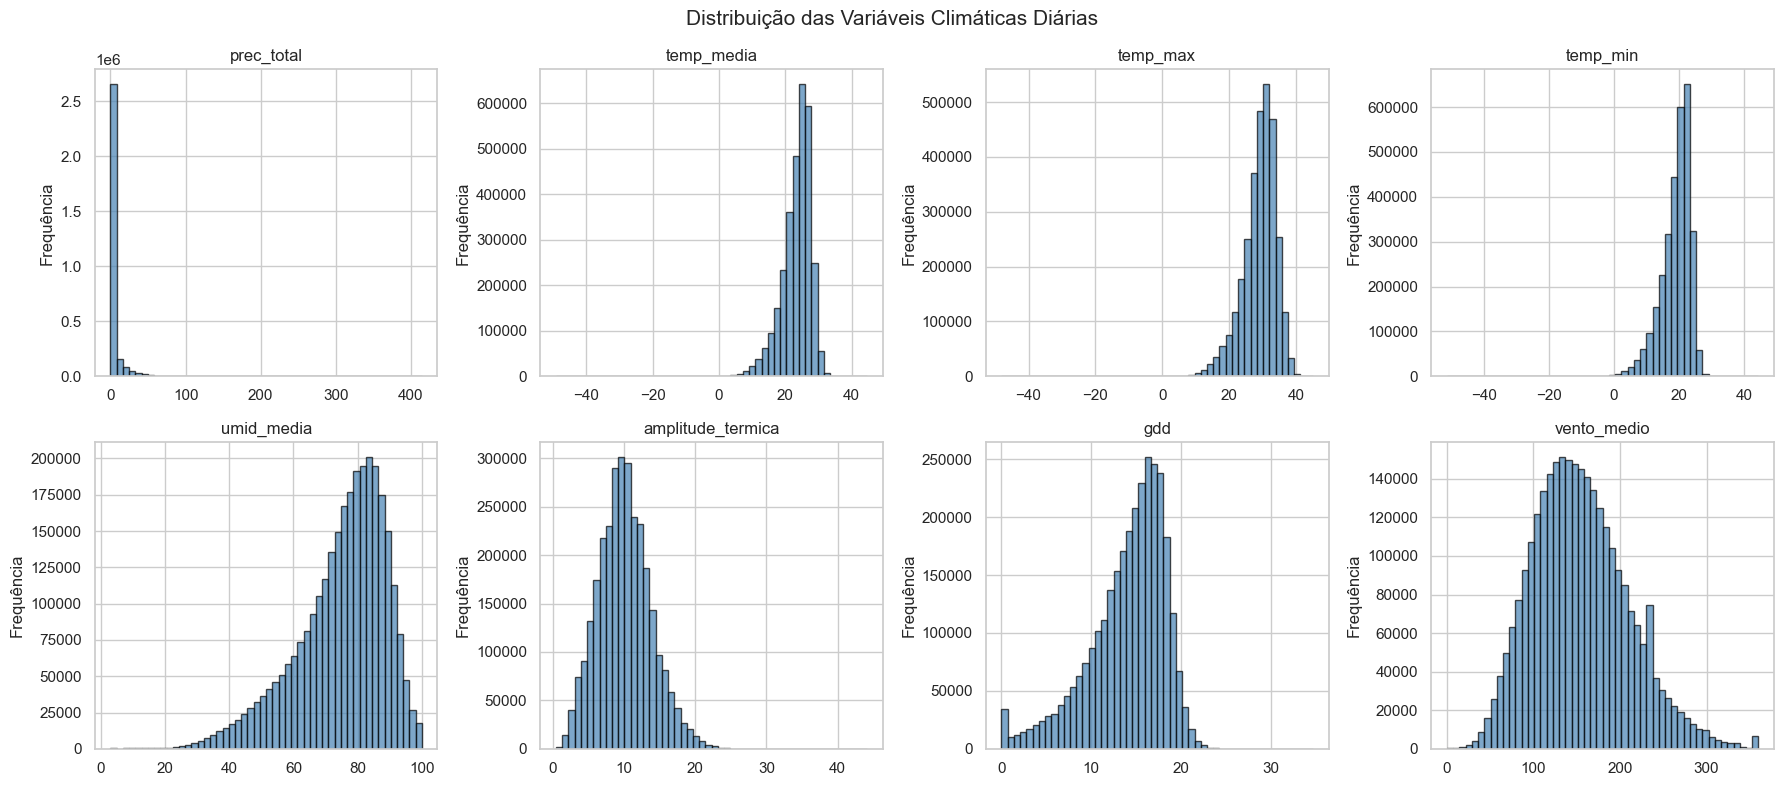

In [22]:
variaveis = ['prec_total', 'temp_media', 'temp_max', 'temp_min', 
             'umid_media', 'amplitude_termica', 'gdd', 'vento_medio']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, var in enumerate(variaveis):
    if var in df.columns:
        df[var].hist(bins=50, ax=axes[i], color='steelblue', edgecolor='black', alpha=0.7)
        axes[i].set_title(var, fontsize=12)
        axes[i].set_ylabel("Frequência")
plt.suptitle("Distribuição das Variáveis Climáticas Diárias", fontsize=15)
plt.tight_layout()
plt.show()

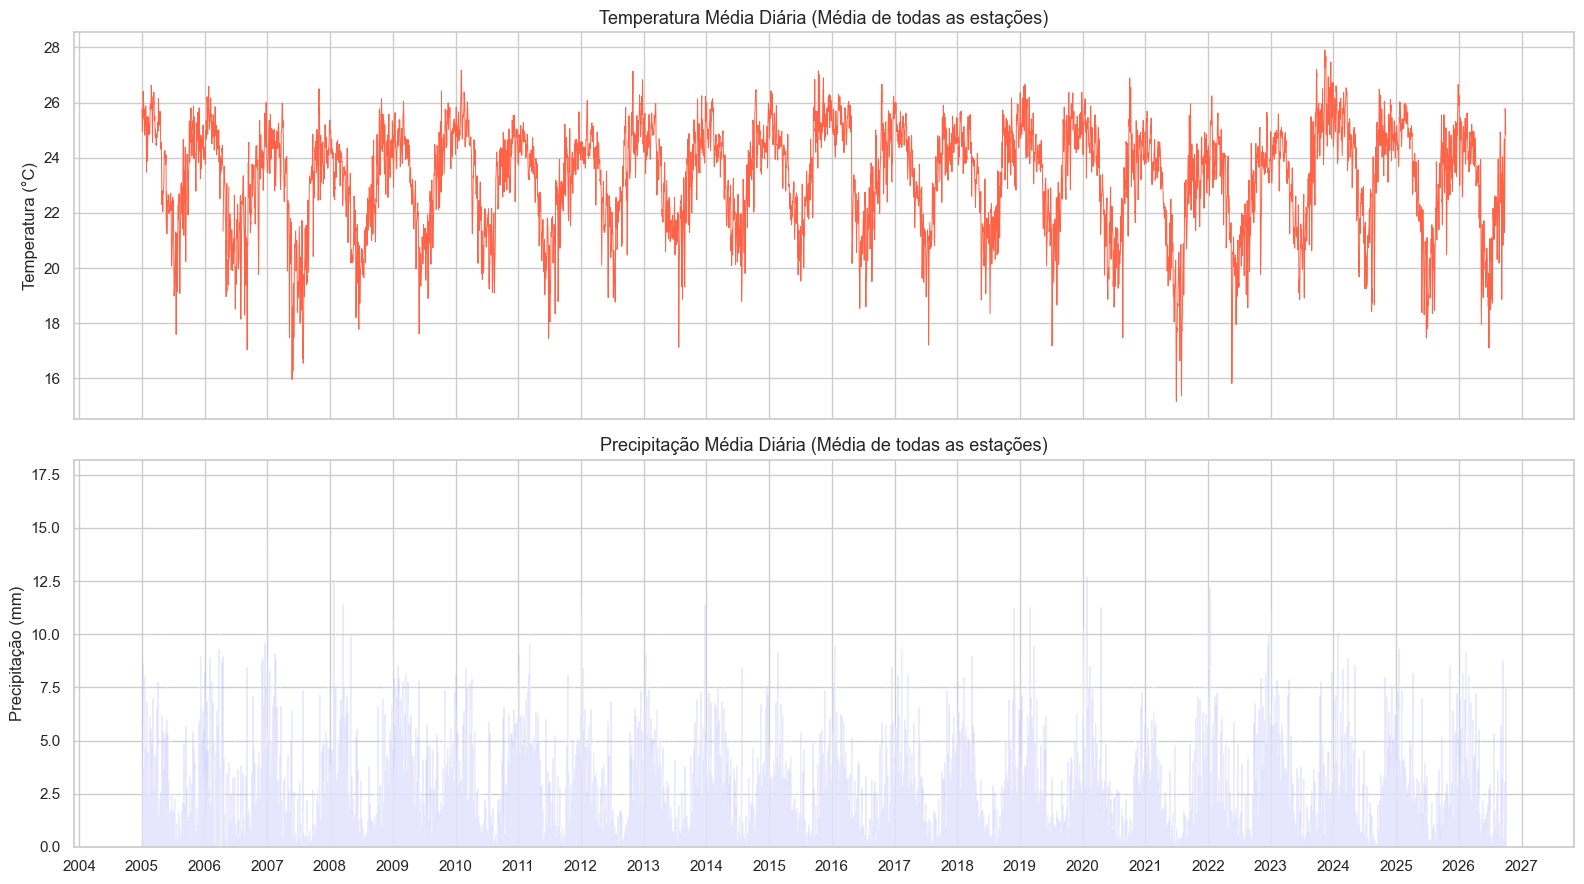

In [34]:
serie = df.groupby('data')[['prec_total', 'temp_media']].mean().reset_index()
serie = serie.set_index('data').asfreq('D').reset_index()  # insere NaN onde falta dia

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

axes[0].plot(serie['data'], serie['temp_media'], linewidth=0.7, color='tomato')
axes[0].set_title("Temperatura Média Diária (Média de todas as estações)")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[1].bar(serie['data'], serie['prec_total'], width=1, color='blue', alpha=0.2)
axes[1].set_title("Precipitação Média Diária (Média de todas as estações)")
axes[1].set_ylabel("Precipitação (mm)")

plt.tight_layout()
plt.show()

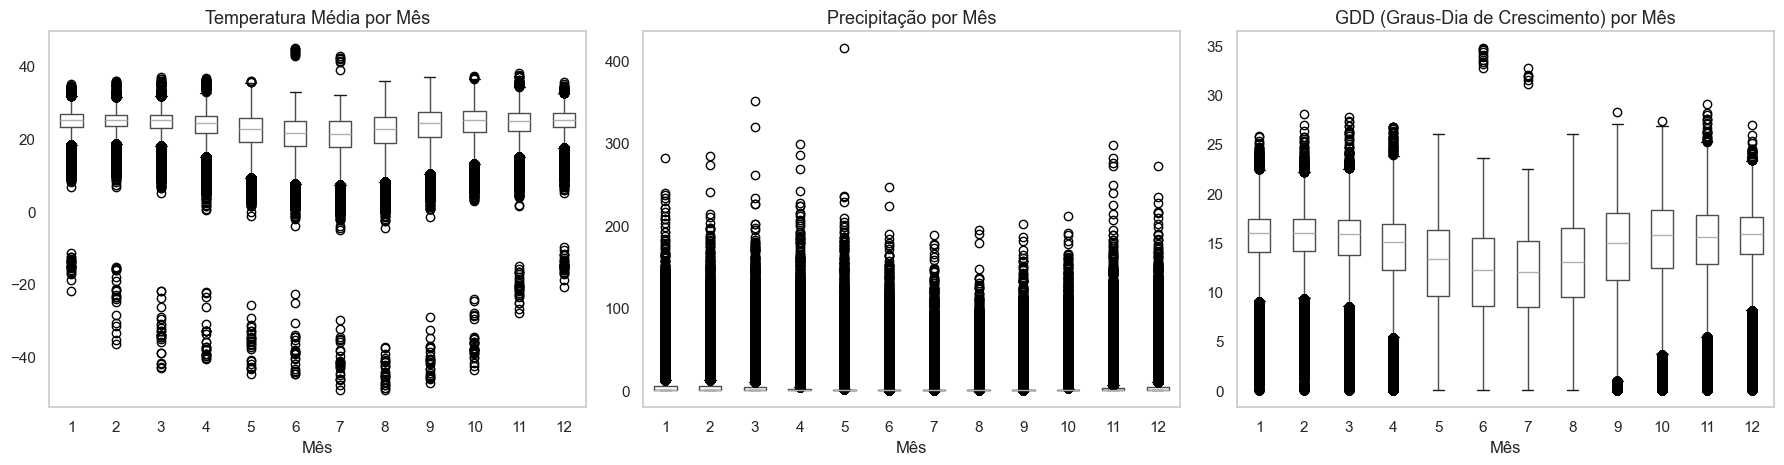

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df.boxplot(column='temp_media', by='mes', ax=axes[0], grid=False)
axes[0].set_title('Temperatura Média por Mês')
axes[0].set_xlabel('Mês')

df.boxplot(column='prec_total', by='mes', ax=axes[1], grid=False)
axes[1].set_title('Precipitação por Mês')
axes[1].set_xlabel('Mês')

df.boxplot(column='gdd', by='mes', ax=axes[2], grid=False)
axes[2].set_title('GDD (Graus-Dia de Crescimento) por Mês')
axes[2].set_xlabel('Mês')

plt.suptitle('')  # Remove o título automático feio do boxplot
plt.tight_layout()
plt.show()

Resumo por UF (ordenado por temperatura):
    temp_media  prec_media  gdd_medio  n_dias  n_estacoes
uf                                                       
PI       27.47        2.12      17.93  104712          23
RR       27.38        3.89      18.05    4926           3
RN       27.31        2.08      17.73   37965           9
MA       27.07        3.46      17.71   86156          18
CE       26.89        2.01      17.55   74680          16
AM       26.74        5.79      17.57   88032          25
PA       26.60        5.06      17.34  136006          35
AP       26.47        6.73      17.27   11038           4
TO       26.19        3.66      16.90   88153          20
RO       25.79        5.42      16.66   20392           7
AL       25.76        2.48      16.39   36531           7
PB       25.34        2.45      15.94   48770           9
SE       25.29        2.42      15.94   30213           7
AC       25.21        4.80      16.30   24584           7
PE       25.16        1.87    

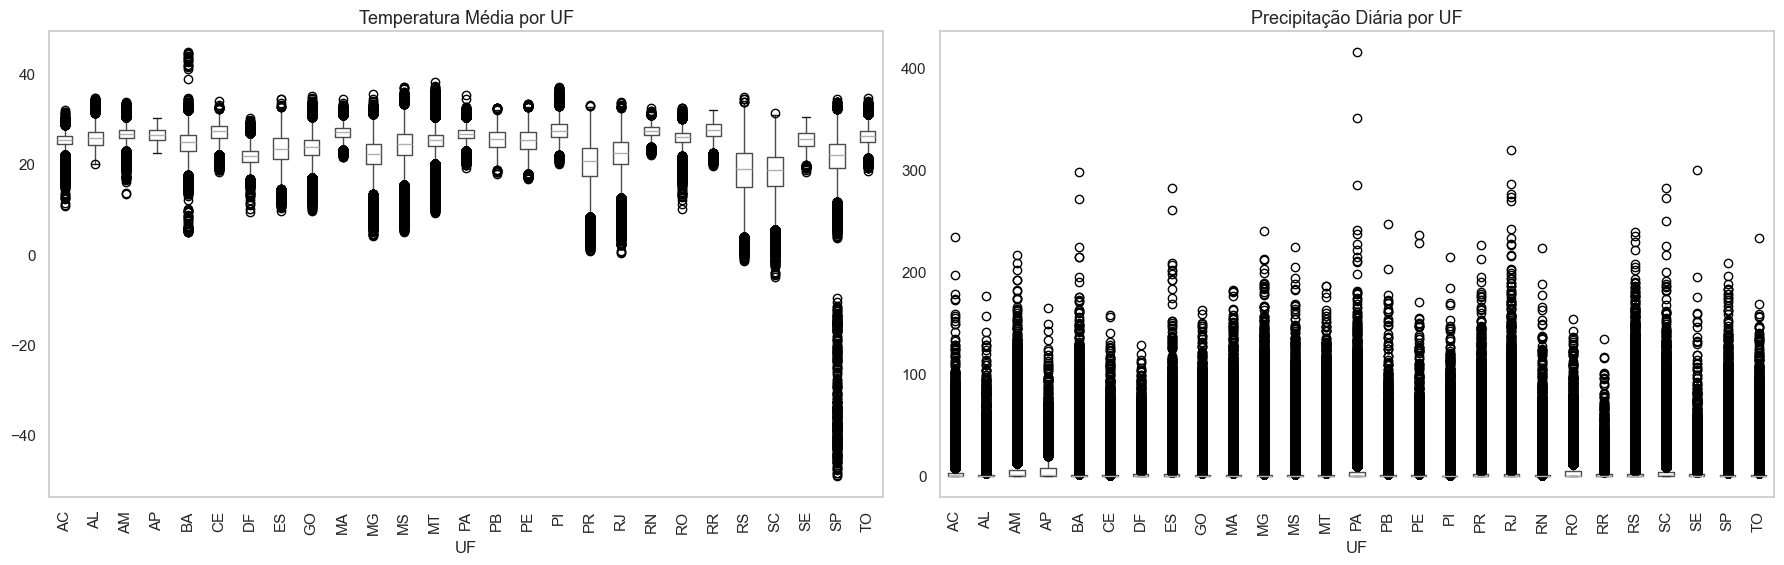

In [36]:
resumo_uf = df.groupby('uf').agg(
    temp_media=('temp_media', 'mean'),
    prec_media=('prec_total', 'mean'),
    gdd_medio=('gdd', 'mean'),
    n_dias=('data', 'count'),
    n_estacoes=('codigo_estacao', 'nunique')
).sort_values('temp_media', ascending=False).round(2)

print("Resumo por UF (ordenado por temperatura):")
print(resumo_uf)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
df.boxplot(column='temp_media', by='uf', ax=axes[0], grid=False)
axes[0].set_title('Temperatura Média por UF')
axes[0].set_xlabel('UF')

df.boxplot(column='prec_total', by='uf', ax=axes[1], grid=False)
axes[1].set_title('Precipitação Diária por UF')
axes[1].set_xlabel('UF')

plt.suptitle('')
for ax in axes:
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

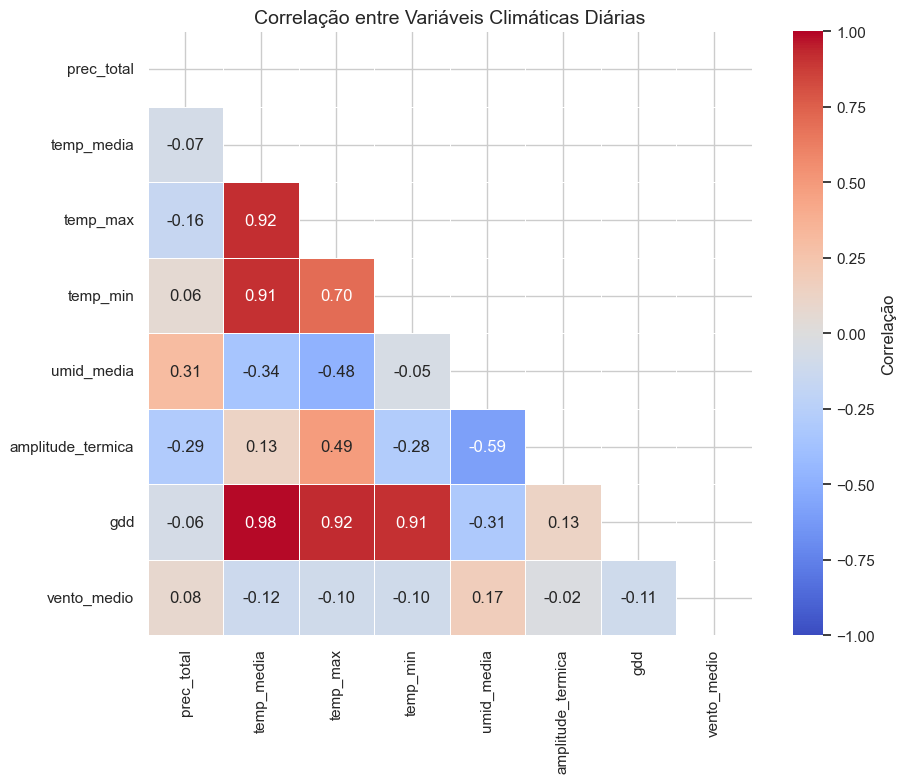

In [16]:
colunas_corr = ['prec_total', 'temp_media', 'temp_max', 'temp_min', 
                'umid_media', 'amplitude_termica', 'gdd', 'vento_medio']
colunas_corr = [c for c in colunas_corr if c in df.columns]
corr = df[colunas_corr].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax, cbar_kws={'label': 'Correlação'})
ax.set_title('Correlação entre Variáveis Climáticas Diárias', fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
# Top valores extremos por variável
for var in ['prec_total', 'temp_max', 'temp_min', 'vento_medio']:
    print(f"\n=== Top 5 maiores valores de {var} ===")
    print(df.nlargest(5, var)[['data', 'codigo_estacao', 'uf', var]].to_string(index=False))
    
    print(f"--- Top 5 menores valores de {var} ---")
    print(df.nsmallest(5, var)[['data', 'codigo_estacao', 'uf', var]].to_string(index=False))

# Detecção de outliers via IQR
print("\n=== Outliers por IQR (1.5x) ===")
for var in ['temp_media', 'prec_total', 'gdd']:
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    iqr = q3 - q1
    n_outliers = ((df[var] < q1 - 1.5*iqr) | (df[var] > q3 + 1.5*iqr)).sum()
    pct = (n_outliers / len(df.dropna(subset=[var]))) * 100
    print(f"  {var}: {n_outliers} outliers ({pct:.2f}%)")


=== Top 5 maiores valores de prec_total ===
      data codigo_estacao uf  prec_total
2019-05-02           A213 PA       414.6
2009-03-16           A227 PA       350.6
2013-03-18           A618 RJ       318.8
2010-04-12           A421 SE       299.0
2013-11-28           A444 BA       297.2
--- Top 5 menores valores de prec_total ---
      data codigo_estacao uf  prec_total
2026-01-09           A001 DF         0.0
2026-01-10           A001 DF         0.0
2026-01-11           A001 DF         0.0
2026-01-12           A001 DF         0.0
2026-01-13           A001 DF         0.0

=== Top 5 maiores valores de temp_max ===
      data codigo_estacao uf  temp_max
2018-09-04           A364 PI      45.0
2018-10-11           A364 PI      45.0
2008-10-27           A907 MT      45.0
2007-06-21           A401 BA      45.0
2007-06-22           A401 BA      45.0
--- Top 5 menores valores de temp_max ---
      data codigo_estacao uf  temp_max
2020-08-18           C891 SP     -48.1
2020-07-19           C

Período esperado: 7943 dias (2005-01-01 a 2026-09-30)

10 estações com MENOR cobertura:
codigo_estacao  dias_presentes   data_min   data_max  pct_cobertura
          B849              10 2026-08-07 2026-08-25            0.1
          B845               7 2026-04-21 2026-06-03            0.1
          S105              17 2017-02-03 2017-03-07            0.2
          B848              16 2026-07-16 2026-08-19            0.2
          B856              31 2026-04-21 2026-09-22            0.4
          A968              30 2026-09-01 2026-09-30            0.4
          A959              34 2026-05-06 2026-09-27            0.4
          S108              38 2017-02-03 2018-04-23            0.5
          A948              45 2026-02-13 2026-09-30            0.6
          A390              50 2026-08-12 2026-09-30            0.6

10 estações com MAIOR cobertura:
codigo_estacao  dias_presentes   data_min   data_max  pct_cobertura
          A408            7566 2005-01-01 2026-07-09          

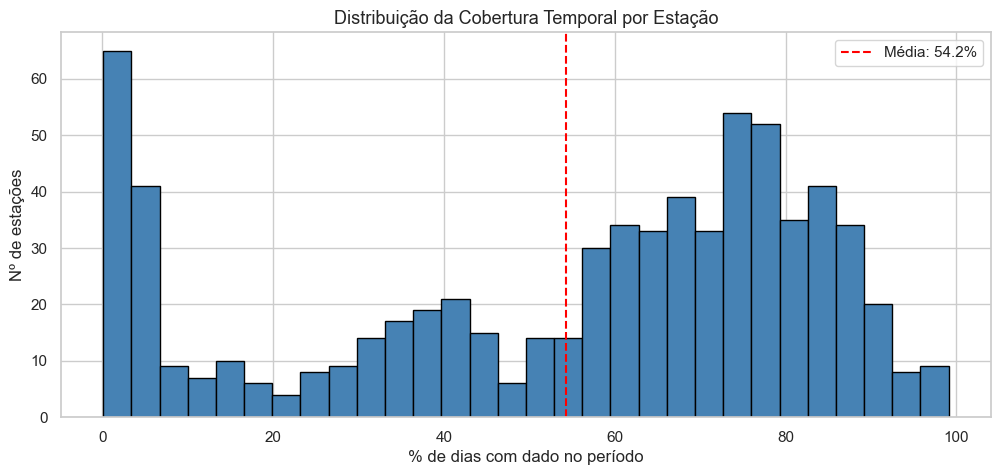

In [18]:
# Para cada estação, calcula quantos dias existem no período esperado vs quantos efetivamente tem
periodo_esperado = (df['data'].max() - df['data'].min()).days + 1

gaps_estacao = df.groupby('codigo_estacao').agg(
    dias_presentes=('data', 'count'),
    data_min=('data', 'min'),
    data_max=('data', 'max')
).reset_index()
gaps_estacao['pct_cobertura'] = (gaps_estacao['dias_presentes'] / periodo_esperado * 100).round(1)
gaps_estacao = gaps_estacao.sort_values('pct_cobertura')

print(f"Período esperado: {periodo_esperado} dias ({df['data'].min().date()} a {df['data'].max().date()})")
print("\n10 estações com MENOR cobertura:")
print(gaps_estacao.head(10).to_string(index=False))
print("\n10 estações com MAIOR cobertura:")
print(gaps_estacao.tail(10).to_string(index=False))

# Histograma de cobertura
plt.figure(figsize=(12, 5))
gaps_estacao['pct_cobertura'].hist(bins=30, color='steelblue', edgecolor='black')
plt.axvline(gaps_estacao['pct_cobertura'].mean(), color='red', linestyle='--', label=f'Média: {gaps_estacao["pct_cobertura"].mean():.1f}%')
plt.title('Distribuição da Cobertura Temporal por Estação')
plt.xlabel('% de dias com dado no período')
plt.ylabel('Nº de estações')
plt.legend()
plt.show()

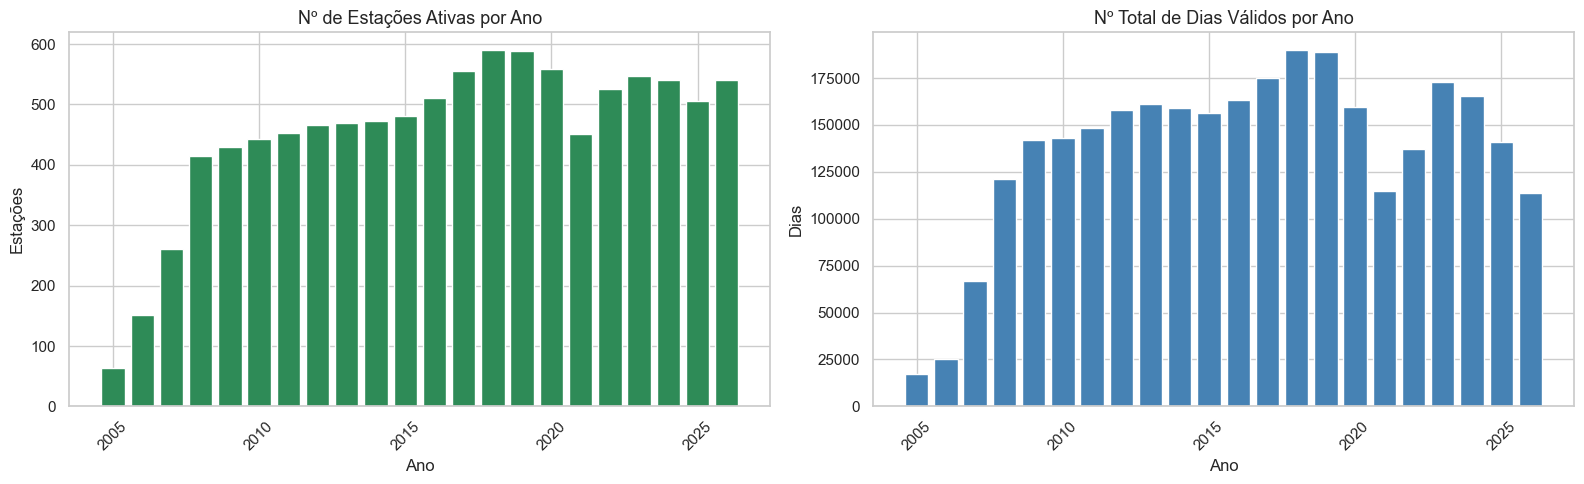


Estações ativas por ano:
ano
2005     63
2006    151
2007    261
2008    415
2009    430
2010    443
2011    453
2012    466
2013    470
2014    472
2015    481
2016    511
2017    556
2018    590
2019    588
2020    559
2021    451
2022    526
2023    547
2024    541
2025    506
2026    540


In [19]:
estacoes_por_ano = df.groupby('ano')['codigo_estacao'].nunique()
dias_por_ano = df.groupby('ano').size()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(estacoes_por_ano.index, estacoes_por_ano.values, color='seagreen')
axes[0].set_title('Nº de Estações Ativas por Ano')
axes[0].set_xlabel('Ano')
axes[0].set_ylabel('Estações')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(dias_por_ano.index, dias_por_ano.values, color='steelblue')
axes[1].set_title('Nº Total de Dias Válidos por Ano')
axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Dias')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Tabela resumo
print("\nEstações ativas por ano:")
print(estacoes_por_ano.to_string())